<a href="https://colab.research.google.com/github/TheSnehaSharma/Van-Der-Pol/blob/main/Van_Der_Pol_Surrogate_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from scipy.integrate import solve_ivp
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import time
import math
import random

# Device
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

# Reproducibility
def set_seed(seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)
    random.seed(seed)

set_seed(42)

torch.set_default_dtype(torch.float64)

Using device: cpu


In [20]:
def approx_period(mu):
    return max(2.0 * math.pi,
               (3.0 - 2.0 * math.log(2.0)) * mu)


def reference_solution(mu, T, x0=2.0, v0=0.0,
                       n_eval=1000):

    def rhs(t, y):
        x, v = y

        dx = v
        dv = mu * (1 - x**2) * v - x

        return [dx, dv]

    def jac(t, y):
        x, v = y

        return [
            [0.0, 1.0],
            [-2.0 * mu * x * v - 1.0,
             mu * (1.0 - x**2)]
        ]

    t_eval = np.linspace(0, T, n_eval)

    sol = solve_ivp(
        rhs,
        (0, T),
        [x0, v0],
        method="Radau",
        jac=jac,
        t_eval=t_eval,
        rtol=1e-9,
        atol=1e-11
    )

    if not sol.success:
        raise RuntimeError(sol.message)

    return sol.t, sol.y[0], sol.y[1]

In [21]:
# Dataset parameters

N_TRAJ = 300
N_EVAL = 1000

MU_VALUES = np.linspace(0.5, 3.0, N_TRAJ)

data = []

start_time = time.time()

for i, mu in enumerate(MU_VALUES):

    # Different initial conditions
    x0 = np.random.uniform(1.0, 3.0)
    v0 = np.random.uniform(-0.5, 0.5)

    # Simulation time
    T = 2 * approx_period(mu)

    t, x, v = reference_solution(
        mu=mu,
        T=T,
        x0=x0,
        v0=v0,
        n_eval=N_EVAL
    )

    # Store trajectory
    for j in range(len(t)):

        data.append([
            t[j],
            mu,
            x0,
            v0,
            x[j],
            v[j],
            i
        ])

    print(f"Trajectory {i+1}/{N_TRAJ} generated")

df = pd.DataFrame(
    data,
    columns=[
        "t", "mu", "x0", "v0",
        "x", "v", "trajectory_id"
    ]
)

print("\nDataset generated")
print(df.head())
print("Dataset shape:", df.shape)

print("Generation time:",
      round(time.time() - start_time, 2), "seconds")

Trajectory 1/300 generated
Trajectory 2/300 generated
Trajectory 3/300 generated
Trajectory 4/300 generated
Trajectory 5/300 generated
Trajectory 6/300 generated
Trajectory 7/300 generated
Trajectory 8/300 generated
Trajectory 9/300 generated
Trajectory 10/300 generated
Trajectory 11/300 generated
Trajectory 12/300 generated
Trajectory 13/300 generated
Trajectory 14/300 generated
Trajectory 15/300 generated
Trajectory 16/300 generated
Trajectory 17/300 generated
Trajectory 18/300 generated
Trajectory 19/300 generated
Trajectory 20/300 generated
Trajectory 21/300 generated
Trajectory 22/300 generated
Trajectory 23/300 generated
Trajectory 24/300 generated
Trajectory 25/300 generated
Trajectory 26/300 generated
Trajectory 27/300 generated
Trajectory 28/300 generated
Trajectory 29/300 generated
Trajectory 30/300 generated
Trajectory 31/300 generated
Trajectory 32/300 generated
Trajectory 33/300 generated
Trajectory 34/300 generated
Trajectory 35/300 generated
Trajectory 36/300 generated
T

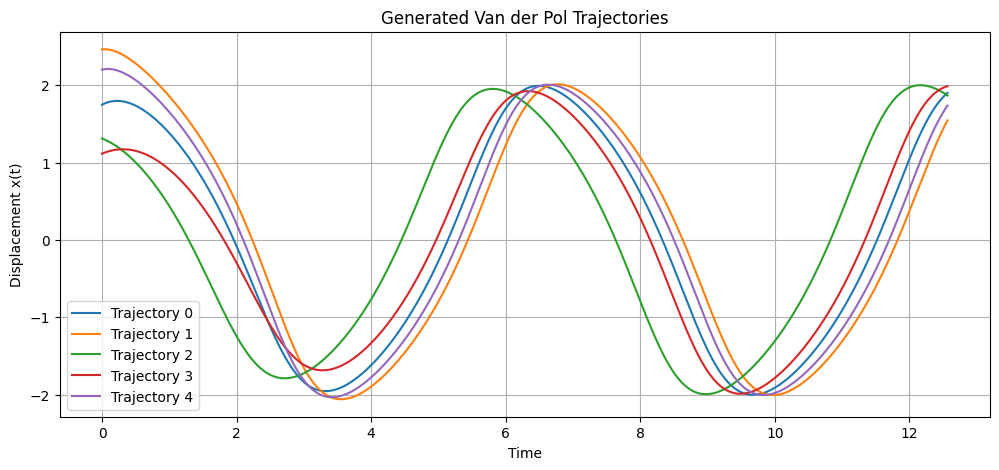

In [22]:
plt.figure(figsize=(12, 5))

for trajectory in df["trajectory_id"].unique()[:5]:

    temp = df[df["trajectory_id"] == trajectory]

    plt.plot(temp["t"], temp["x"],
             label=f"Trajectory {trajectory}")

plt.xlabel("Time")
plt.ylabel("Displacement x(t)")
plt.title("Generated Van der Pol Trajectories")
plt.legend()
plt.grid()
plt.show()

In [23]:
# Input and output features

features = ["t", "mu", "x0", "v0"]
targets = ["x", "v"]

X = df[features].values
Y = df[targets].values

# Split by trajectory IDs
trajectory_ids = df["trajectory_id"].unique()

train_ids, temp_ids = train_test_split(
    trajectory_ids,
    test_size=0.4,
    random_state=42
)

val_ids, test_ids = train_test_split(
    temp_ids,
    test_size=0.5,
    random_state=42
)

train_df = df[df.trajectory_id.isin(train_ids)]
val_df = df[df.trajectory_id.isin(val_ids)]
test_df = df[df.trajectory_id.isin(test_ids)]

# Extract features and targets

X_train = train_df[features].values
Y_train = train_df[targets].values

X_val = val_df[features].values
Y_val = val_df[targets].values

X_test = test_df[features].values
Y_test = test_df[targets].values

# Scaling
scaler_input = MinMaxScaler()
scaler_output = MinMaxScaler()

X_train_scaled = scaler_input.fit_transform(X_train)
X_val_scaled = scaler_input.transform(X_val)
X_test_scaled = scaler_input.transform(X_test)

Y_train_scaled = scaler_output.fit_transform(Y_train)
Y_val_scaled = scaler_output.transform(Y_val)
Y_test_scaled = scaler_output.transform(Y_test)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (180000, 4)
Validation: (60000, 4)
Testing: (60000, 4)


In [24]:
from torch.utils.data import TensorDataset, DataLoader

BATCH_SIZE = 256

train_dataset = TensorDataset(
    torch.tensor(X_train_scaled),
    torch.tensor(Y_train_scaled)
)

val_dataset = TensorDataset(
    torch.tensor(X_val_scaled),
    torch.tensor(Y_val_scaled)
)

test_dataset = TensorDataset(
    torch.tensor(X_test_scaled),
    torch.tensor(Y_test_scaled)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Training batches: 704
Validation batches: 235
Testing batches: 235


In [25]:
class MLP(nn.Module):

    def __init__(self, width=64, depth=4, n_out=2):

        super().__init__()

        layers = [
            nn.Linear(4, width),
            nn.Tanh()
        ]

        for _ in range(depth - 1):

            layers += [
                nn.Linear(width, width),
                nn.Tanh()
            ]

        layers += [nn.Linear(width, n_out)]

        self.net = nn.Sequential(*layers)

        for m in self.net:

            if isinstance(m, nn.Linear):

                nn.init.xavier_normal_(m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, x):
        return self.net(x)


model = MLP(
    width=64,
    depth=4,
    n_out=2
).to(DEVICE)

print(model)

MLP(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): Tanh()
    (4): Linear(in_features=64, out_features=64, bias=True)
    (5): Tanh()
    (6): Linear(in_features=64, out_features=64, bias=True)
    (7): Tanh()
    (8): Linear(in_features=64, out_features=2, bias=True)
  )
)


In [26]:
LEARNING_RATE = 0.001
N_EPOCHS = 500

loss_function = nn.L1Loss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=N_EPOCHS
)

best_val = float("inf")

train_losses = []
val_losses = []

In [27]:
start_time = time.time()

for epoch in range(N_EPOCHS):

    # Training
    model.train()

    train_loss = 0

    for X_batch, Y_batch in train_loader:

        X_batch = X_batch.to(DEVICE)
        Y_batch = Y_batch.to(DEVICE)

        optimizer.zero_grad()

        prediction = model(X_batch)

        loss = loss_function(
            prediction,
            Y_batch
        )

        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    train_loss /= len(train_loader)

    # Validation
    model.eval()

    val_loss = 0

    with torch.no_grad():

        for X_batch, Y_batch in val_loader:

            X_batch = X_batch.to(DEVICE)
            Y_batch = Y_batch.to(DEVICE)

            prediction = model(X_batch)

            loss = loss_function(
                prediction,
                Y_batch
            )

            val_loss += loss.item()

    val_loss /= len(val_loader)

    scheduler.step()
    if val_loss < best_val:
        best_val = val_loss
        torch.save(model.state_dict(), "best.pth")

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    if epoch % 50 == 0:

        print(
            f"Epoch [{epoch}/{N_EPOCHS}] "
            f"Train Loss: {train_loss:.6f} "
            f"Val Loss: {val_loss:.6f}"
        )

training_time = time.time() - start_time

print("\nTraining completed")
print("Training time:", round(training_time, 2), "seconds")
model.load_state_dict(torch.load("best.pth"))
print("Best validation loss:", round(best_val, 6))

Epoch [0/500] Train Loss: 0.157549 Val Loss: 0.111003
Epoch [50/500] Train Loss: 0.005364 Val Loss: 0.005905
Epoch [100/500] Train Loss: 0.004375 Val Loss: 0.004363
Epoch [150/500] Train Loss: 0.003760 Val Loss: 0.005625
Epoch [200/500] Train Loss: 0.003053 Val Loss: 0.004312
Epoch [250/500] Train Loss: 0.002587 Val Loss: 0.003658
Epoch [300/500] Train Loss: 0.001992 Val Loss: 0.001829
Epoch [350/500] Train Loss: 0.001518 Val Loss: 0.001650
Epoch [400/500] Train Loss: 0.001154 Val Loss: 0.001375
Epoch [450/500] Train Loss: 0.000976 Val Loss: 0.001236

Training completed
Training time: 2348.55 seconds
Best validation loss: 0.001154


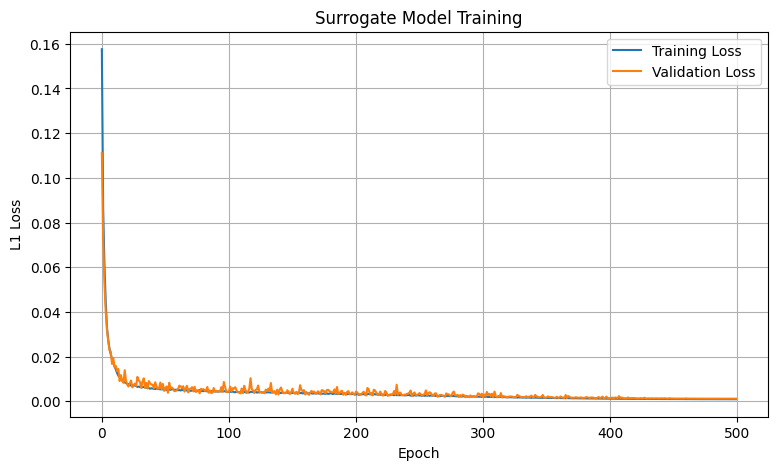

In [28]:
plt.figure(figsize=(9, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("L1 Loss")
plt.title("Surrogate Model Training")

plt.legend()
plt.grid()
plt.show()

In [29]:
model.eval()

with torch.no_grad():

    X_tensor = torch.tensor(
        X_test_scaled
    ).to(DEVICE)

    Y_pred_scaled = model(X_tensor).cpu().numpy()

# Convert predictions back to original scale

Y_pred = scaler_output.inverse_transform(
    Y_pred_scaled
)

Y_actual = Y_test

x_actual = Y_actual[:, 0]
v_actual = Y_actual[:, 1]

x_pred = Y_pred[:, 0]
v_pred = Y_pred[:, 1]

In [30]:
def calculate_metrics(actual, predicted):

    mae = mean_absolute_error(
        actual, predicted
    )

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    r2 = r2_score(
        actual, predicted
    )

    return mae, rmse, r2


x_metrics = calculate_metrics(
    x_actual, x_pred
)

v_metrics = calculate_metrics(
    v_actual, v_pred
)

results = pd.DataFrame({
    "Variable": ["Displacement x", "Velocity v"],
    "MAE": [x_metrics[0], v_metrics[0]],
    "RMSE": [x_metrics[1], v_metrics[1]],
    "R2": [x_metrics[2], v_metrics[2]]
})

print(results)

         Variable       MAE      RMSE        R2
0  Displacement x  0.005606  0.012584  0.999933
1      Velocity v  0.010168  0.026652  0.999627


In [31]:
# Select one unseen test trajectory

selected_id = test_ids[0]

comparison_df = test_df[
    test_df["trajectory_id"] == selected_id
].copy()

# Original inputs
X_compare = comparison_df[features].values

# Scale inputs
X_compare_scaled = scaler_input.transform(
    X_compare
)

# Predict
model.eval()

with torch.no_grad():

    X_compare_tensor = torch.tensor(
        X_compare_scaled
    ).to(DEVICE)

    Y_compare_scaled = model(
        X_compare_tensor
    ).cpu().numpy()

# Inverse transform
Y_compare = scaler_output.inverse_transform(
    Y_compare_scaled
)

t_compare = comparison_df["t"].values

x_numerical = comparison_df["x"].values
v_numerical = comparison_df["v"].values

x_surrogate = Y_compare[:, 0]
v_surrogate = Y_compare[:, 1]

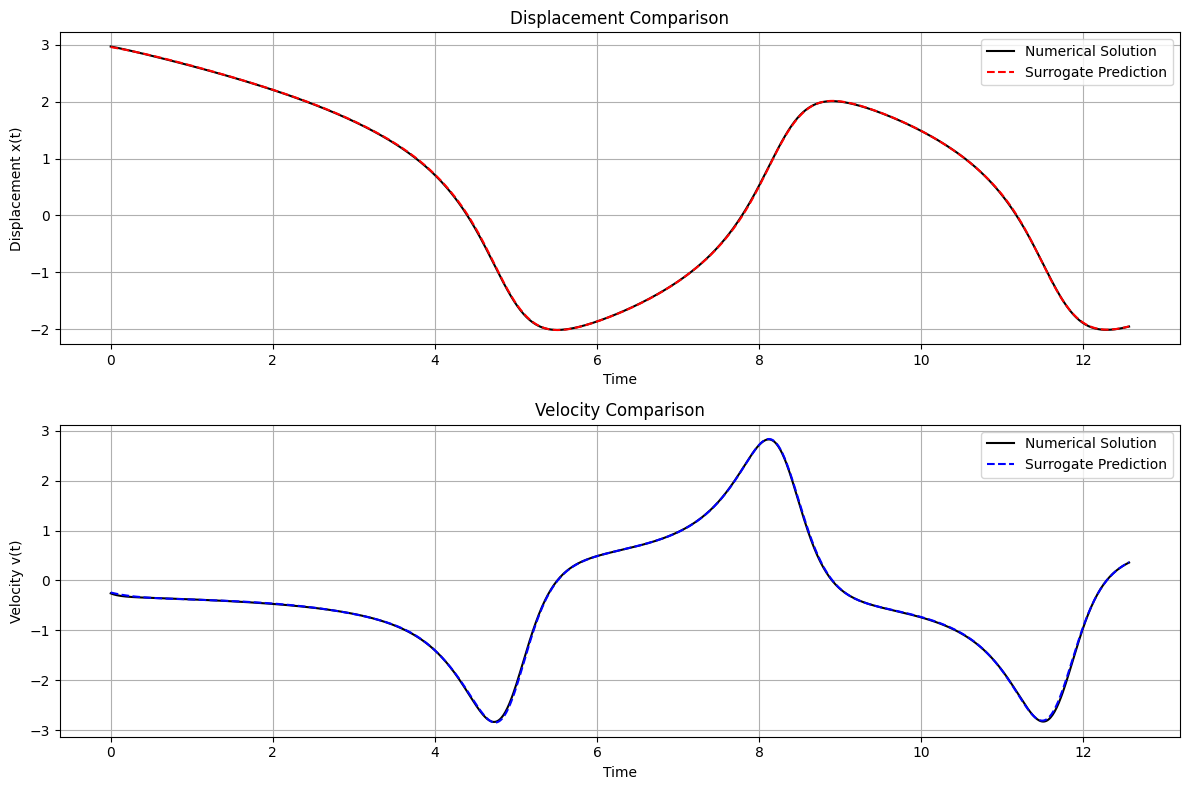

In [32]:
fig, axs = plt.subplots(2, 1, figsize=(12, 8))

# Displacement
axs[0].plot(
    t_compare,
    x_numerical,
    "k-",
    label="Numerical Solution"
)

axs[0].plot(
    t_compare,
    x_surrogate,
    "r--",
    label="Surrogate Prediction"
)

axs[0].set_xlabel("Time")
axs[0].set_ylabel("Displacement x(t)")
axs[0].set_title("Displacement Comparison")
axs[0].legend()
axs[0].grid()

# Velocity
axs[1].plot(
    t_compare,
    v_numerical,
    "k-",
    label="Numerical Solution"
)

axs[1].plot(
    t_compare,
    v_surrogate,
    "b--",
    label="Surrogate Prediction"
)

axs[1].set_xlabel("Time")
axs[1].set_ylabel("Velocity v(t)")
axs[1].set_title("Velocity Comparison")
axs[1].legend()
axs[1].grid()

plt.tight_layout()
plt.show()

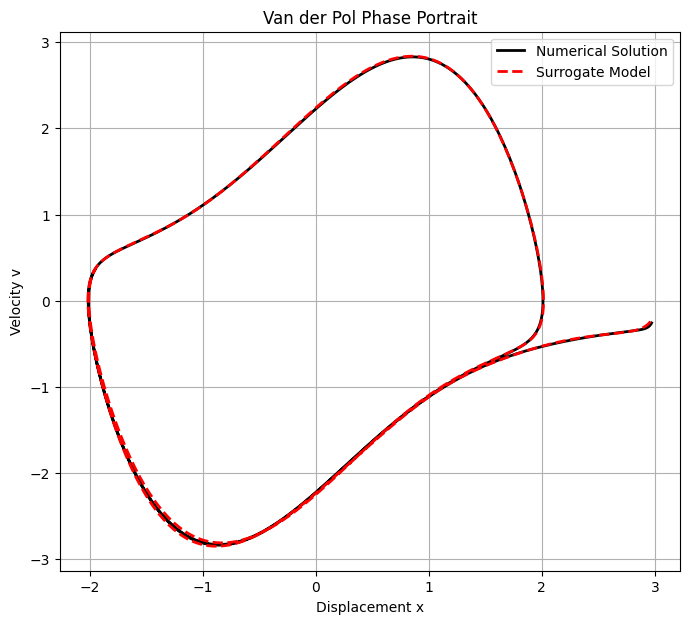

In [33]:
plt.figure(figsize=(8, 7))

plt.plot(
    x_numerical,
    v_numerical,
    "k-",
    linewidth=2,
    label="Numerical Solution"
)

plt.plot(
    x_surrogate,
    v_surrogate,
    "r--",
    linewidth=2,
    label="Surrogate Model"
)

plt.xlabel("Displacement x")
plt.ylabel("Velocity v")

plt.title("Van der Pol Phase Portrait")

plt.legend()
plt.grid()
plt.show()

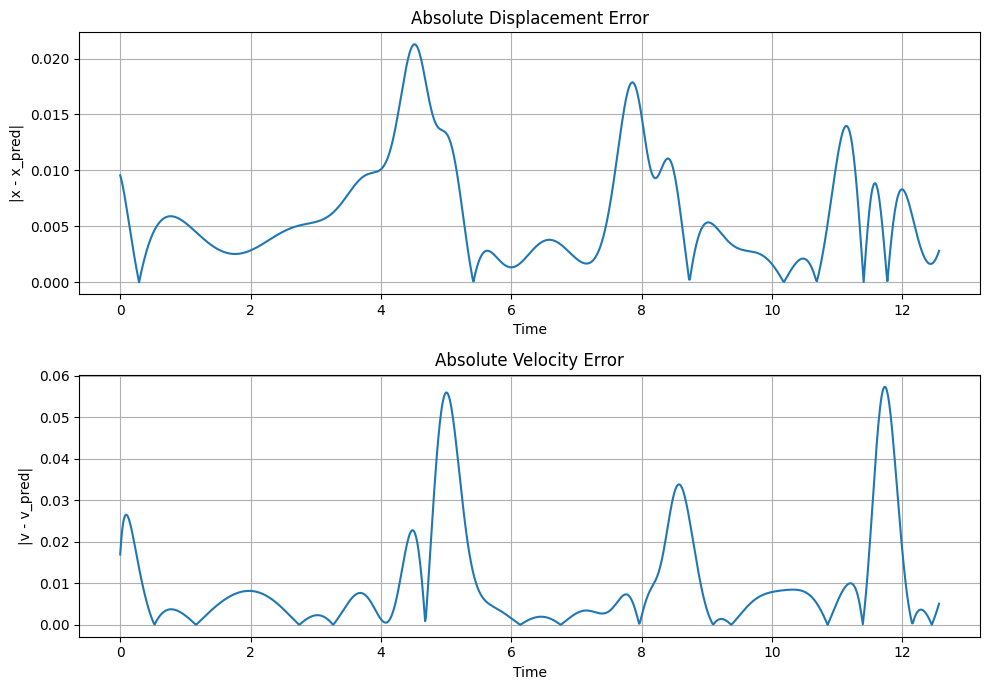

In [34]:
error_x = np.abs(
    x_numerical - x_surrogate
)

error_v = np.abs(
    v_numerical - v_surrogate
)

fig, axs = plt.subplots(2, 1, figsize=(10, 7))

axs[0].plot(t_compare, error_x)
axs[0].set_title("Absolute Displacement Error")
axs[0].set_ylabel("|x - x_pred|")
axs[0].set_xlabel("Time")
axs[0].grid()

axs[1].plot(t_compare, error_v)
axs[1].set_title("Absolute Velocity Error")
axs[1].set_ylabel("|v - v_pred|")
axs[1].set_xlabel("Time")
axs[1].grid()

plt.tight_layout()
plt.show()

In [35]:
torch.save(
    model.state_dict(),
    "van_der_pol_surrogate.pth"
)

import pickle

with open("scaler_input.pkl", "wb") as f:
    pickle.dump(scaler_input, f)

with open("scaler_output.pkl", "wb") as f:
    pickle.dump(scaler_output, f)

print("Model and scalers saved successfully.")

Model and scalers saved successfully.


In [36]:
# Numerical solver time

mu_test = float(comparison_df["mu"].iloc[0])
x0_test = float(comparison_df["x0"].iloc[0])
v0_test = float(comparison_df["v0"].iloc[0])

T_test = comparison_df["t"].iloc[-1]

start = time.perf_counter()

t_ref, x_ref, v_ref = reference_solution(
    mu_test,
    T_test,
    x0_test,
    v0_test,
    n_eval=len(comparison_df)
)

numerical_time = time.perf_counter() - start


# Surrogate prediction time

if DEVICE.type == "cuda":
    torch.cuda.synchronize()

start = time.perf_counter()

with torch.no_grad():
    prediction = model(X_compare_tensor)

if DEVICE.type == "cuda":
    torch.cuda.synchronize()

surrogate_time = time.perf_counter() - start

speedup = numerical_time / surrogate_time

print("Numerical solution time:", numerical_time)
print("Surrogate prediction time:", surrogate_time)
print("Speedup:", speedup, "times")

Numerical solution time: 0.8924352679996446
Surrogate prediction time: 0.004419035999490006
Speedup: 201.9524774413784 times
